**What the IMF Says About Botswana in 2025: A Checked LLM Reading**

IMF Country Report No. 25/325 is the only input. Stored replies in `cache/` mean Run all needs no key.

In [2]:
%pip install -q faiss-cpu==1.15.1 pypdf==7.0.0 msgspec toolz pytesseract
!command -v tesseract > /dev/null || (apt-get -qq update && apt-get -qq install -y tesseract-ocr > /dev/null) || true

In [3]:
import hashlib
import io
import json
import math
import os
import re
import textwrap
import time
from collections import Counter
from pathlib import Path
from typing import Annotated, Literal

import faiss
import matplotlib.pyplot as plt
import msgspec
import numpy as np
import pandas as pd
import pypdf
import pytesseract
import tenacity
import toolz
from PIL import Image
from scipy import stats
from sentence_transformers import SentenceTransformer
from toolz import curried as tc

pd.set_option("display.max_colwidth", 110)
print("pypdf", pypdf.__version__, "| msgspec", msgspec.__version__, "| toolz", toolz.__version__, "| faiss", faiss.__version__)

pypdf 7.0.0 | msgspec 0.22.0 | toolz 0.12.1 | faiss 1.15.1


**Settings**

All choices are in one place. The embedding model was trained on questions and passages, which matches how it is used here.

In [4]:
class Settings(msgspec.Struct, frozen=True):
    pdf: Path = Path("data/IMF_CR_25_325_Botswana_2025_Article_IV.pdf")
    country: str = "Botswana"
    label: str = "IMF Country Report No. 25/325 (December 2025), 2025 Article IV Consultation"
    secret: str = "GEMINI_FREE_KEY"
    writer: str = "gemini-3.7-flash"
    judge: str = "gemini-3.5-flash"
    writer_heat: float = 0.15
    judge_heat: float = 0.0
    output_cap: int = 16384        # thinking tokens count against this limit
    attempts: int = 6
    pause: float = 1.0
    encoder: str = "sentence-transformers/multi-qa-mpnet-base-cos-v1"
    window: int = 320
    overlap: int = 50
    snap: int = 60                 # a window may end up to this many tokens early, at a sentence end
    top_k: int = 5
    pool: int = 30                 # candidates per query in the fusion of Part 4
    summary_words: tuple = (55, 92)
    results: Path = Path("results")
    ledger: Path = Path("cache/ledger.jsonl")
    ocr_store: Path = Path("cache/ocr_pages.json")


CFG = Settings()
CFG.results.mkdir(exist_ok=True)
CFG.ledger.parent.mkdir(exist_ok=True)
assert CFG.pdf.exists(), f"missing {CFG.pdf}"
print(json.dumps(msgspec.to_builtins(CFG, enc_hook=str), indent=1))

{
 "pdf": "data/IMF_CR_25_325_Botswana_2025_Article_IV.pdf",
 "country": "Botswana",
 "label": "IMF Country Report No. 25/325 (December 2025), 2025 Article IV Consultation",
 "secret": "GEMINI_FREE_KEY",
 "writer": "gemini-3.7-flash",
 "judge": "gemini-3.5-flash",
 "writer_heat": 0.15,
 "judge_heat": 0.0,
 "output_cap": 16384,
 "attempts": 6,
 "pause": 1.0,
 "encoder": "sentence-transformers/multi-qa-mpnet-base-cos-v1",
 "window": 320,
 "overlap": 50,
 "snap": 60,
 "top_k": 5,
 "pool": 30,
 "summary_words": [
  55,
  92
 ],
 "results": "results",
 "ledger": "cache/ledger.jsonl",
 "ocr_store": "cache/ocr_pages.json"
}


**Prompts**

The writer copies numbers as printed. The judge is told to look for faults first.

In [5]:
ANALYST = ("You are a macro-financial analyst at a central bank, reading an IMF Article IV package. Work only from "
           "the text supplied. Copy each figure exactly as printed. Do not bring in outside knowledge.")
AUDITOR = ("You audit work derived from an IMF Article IV package, using only the source text supplied. "
           "A fault you fail to report counts as your own error, so look for faults before giving credit.")

PROMPTS = {
    "summary": (ANALYST,
        "Section: {heading} (PDF pages {span}).\nWrite one paragraph of {low} to {high} words saying what this section "
        "concludes, with its key figures as printed and its main recommendation if it makes one. No lists.{hint}\n\n"
        "SECTION TEXT:\n{body}"),
    "mark_summary": (AUDITOR,
        "Compare the PARAGRAPH with the SOURCE, which is the section \"{heading}\".\nGive integer marks from 1 to 5: "
        "consistency (nothing contradicts the source), completeness (the section's main messages are there), "
        "factual_alignment (each figure and claim is in the source). Put each specific fault in faults.\n\n"
        "PARAGRAPH:\n{draft}\n\nSOURCE:\n{body}"),
    "bullets": (ANALYST,
        "These are paragraph summaries of an IMF report, each with a section id. Write {low} to {high} executive "
        "bullets on financial stability and risk for a finance minister. Each is one sentence of at most 35 words and "
        "names the section id it relies on. Together they must cover growth and diamonds, fiscal position and debt, "
        "the exchange rate and reserves, the banking system, and the main risks.{hint}\n\n{digest}"),
    "mark_bullets": (AUDITOR,
        "For each numbered BULLET, decide whether the summary with the id it names supports it (supported, true or "
        "false, with a short reason). Then mark the whole set from 1 to 5 on consistency, completeness and "
        "factual_alignment, and list faults.\n\nBULLETS:\n{listing}\n\nSUMMARIES:\n{digest}"),
    "themes": (ANALYST,
        "Assign each passage the single theme it mainly concerns (primary) and any others it also discusses (others). "
        "Themes: {themes}. Use \"none\" for primary when no theme fits. Return one label per passage id.\n\n{passages}"),
    "points": (ANALYST,
        "From the report text below, list {low} to {high} strengths or growth drivers and {low} to {high} "
        "vulnerabilities of {country}'s economy. For each give a label of at most 8 words, one sentence of explanation, "
        "the pdf_page, and a quote of 8 to 30 words copied exactly from that page. Pages are marked [p.N].\n\n{body}"),
    "mark_points": (AUDITOR,
        "For each numbered POINT decide whether its quote really supports it (supported) and whether it is correctly "
        "classed as a strength or a vulnerability (correct_class), with a short reason.\n\n{listing}"),
    "indicators": (ANALYST,
        "Fill in this indicator sheet for {country} from the pages below. For each field take the figure for the latest "
        "date the package gives, or for a forecast the current year's projection. A document in the package can update "
        "another, so compare dates. Report value, year, pdf_page, source (row label or sentence) and reason. "
        "If no figure is printed, use null for value, year, pdf_page and source and explain why in reason. "
        "Never derive or estimate.\n\nFIELDS:\n{fields}\n\nPAGES:\n{pages}"),
    "audit_numbers": (AUDITOR,
        "Another model took each ITEM from the pages below. Give one verdict per field: CORRECT, WRONG (put the printed "
        "value in page_shows), NOT_FOUND, CORRECTLY_NULL, or MISSED (null was given but a figure is printed; put it in "
        "page_shows), with a short reason. Check that a later dated figure has not replaced the one chosen.\n\n"
        "ITEMS:\n{items}\n\nPAGES:\n{pages}"),
    "series": (ANALYST,
        "Copy every value of these rows from the table: {rows}. Columns in order: {columns}. Use null for a blank or "
        "dash cell.\n\nTABLE (PDF page {page}):\n{table}"),
    "answer": (ANALYST,
        "Question: {question}\n\nAnswer in at most 80 words using only the numbered passages, and cite the ids you used "
        "in square brackets, for example [W012]. If they do not contain the answer, say so, cite nothing and set "
        "answerable to false.\n\nPASSAGES:\n{passages}"),
    "mark_answer": (AUDITOR,
        "Question: {question}\n\nANSWER:\n{answer}\n\nPASSAGES:\n{passages}\n\nMark faithfulness from 1 to 5 (each claim "
        "is backed by the passages) and completeness from 1 to 5 (it gives what the passages say on the question; a "
        "refusal is complete if the passages lack the answer). Give one sentence of reason for each mark."),
    "angles": (ANALYST,
        "Question about an IMF report: {question}\n\nDo not answer it. Rewrite it as one search query of 6 to 15 words "
        "from each of three perspectives, using the terms that specialist would look for: fiscal (a finance ministry "
        "economist), external (a central bank reserves and exchange rate analyst), banking (a bank supervisor)."),
}
print(len(PROMPTS), "prompts:", ", ".join(PROMPTS))

13 prompts: summary, mark_summary, bullets, mark_bullets, themes, points, mark_points, indicators, audit_numbers, series, answer, mark_answer, angles


**Reply types**

Each reply has a fixed type, so a wrong or incomplete reply is caught.

In [6]:
Mark = Annotated[int, msgspec.Meta(ge=1, le=5)]


class Reply(msgspec.Struct, frozen=True, forbid_unknown_fields=True):
    pass


class Paragraph(Reply):
    paragraph: str


class Marks(Reply):
    consistency: Mark
    completeness: Mark
    factual_alignment: Mark
    faults: list[str]


class Bullet(Reply):
    section_id: str
    sentence: str


class BulletSet(Reply):
    bullets: list[Bullet]


class BulletCheck(Reply):
    number: int
    supported: bool
    reason: str


class BulletMarks(Reply):
    checks: list[BulletCheck]
    consistency: Mark
    completeness: Mark
    factual_alignment: Mark
    faults: list[str]


class ThemeTag(Reply):
    passage_id: str
    primary: str
    others: list[str]


class ThemeTags(Reply):
    tags: list[ThemeTag]


class Point(Reply):
    label: str
    explanation: str
    pdf_page: int
    quote: str


class PointSet(Reply):
    strengths: list[Point]
    vulnerabilities: list[Point]


class PointCheck(Reply):
    number: int
    supported: bool
    correct_class: bool
    reason: str


class PointChecks(Reply):
    checks: list[PointCheck]


class Reading(Reply):
    value: float | None
    year: int | None
    pdf_page: int | None
    source: str | None
    reason: str


class IndicatorSheet(Reply):
    gdp_growth_forecast_pct: Reading
    headline_inflation_rate_pct: Reading
    central_bank_policy_rate_pct: Reading
    non_performing_loan_ratio: Reading
    unemployment_rate_pct: Reading
    tier_1_capital_ratio: Reading


class AuditRow(Reply):
    field: str
    verdict: Literal["CORRECT", "WRONG", "NOT_FOUND", "CORRECTLY_NULL", "MISSED"]
    page_shows: float | None
    reason: str


class Audit(Reply):
    rows: list[AuditRow]


class CopiedRow(Reply):
    label: str
    values: list[float | None]


class CopiedTable(Reply):
    rows: list[CopiedRow]


class Answer(Reply):
    answer: str
    citations: list[str]
    answerable: bool


class AnswerMarks(Reply):
    faithfulness: Mark
    completeness: Mark
    faithfulness_reason: str
    completeness_reason: str


class Angles(Reply):
    fiscal: str
    external: str
    banking: str


def inline_refs(node, defs):
    """msgspec writes $ref links; the API is sent one self-contained schema."""
    if isinstance(node, dict):
        if "$ref" in node:
            return inline_refs(defs[node["$ref"].rsplit("/", 1)[1]], defs)
        return {k: inline_refs(v, defs) for k, v in node.items() if k not in ("$defs", "title")}
    if isinstance(node, list):
        return [inline_refs(v, defs) for v in node]
    return node


def schema_of(kind) -> dict:
    raw = msgspec.json.schema(kind)
    return inline_refs(raw, raw.get("$defs", {}))


print(json.dumps(schema_of(Marks)))

{"type": "object", "properties": {"consistency": {"type": "integer", "minimum": 1, "maximum": 5}, "completeness": {"type": "integer", "minimum": 1, "maximum": 5}, "factual_alignment": {"type": "integer", "minimum": 1, "maximum": 5}, "faults": {"type": "array", "items": {"type": "string"}}}, "required": ["consistency", "completeness", "factual_alignment", "faults"], "additionalProperties": false}


**Model calls**

All calls go through `ask()`. Replies are saved, failures are retried, and a bad reply gets one repair.

In [7]:
class Stop(RuntimeError):
    """Waiting or retrying cannot help."""


def secret_key():
    try:
        from google.colab import userdata
        return userdata.get(CFG.secret)
    except Exception:
        return os.environ.get(CFG.secret)


class Ledger:
    def __init__(self, path: Path):
        self.path = path
        lines = path.read_text(encoding="utf-8").splitlines() if path.exists() else []
        self.rows = dict(toolz.pluck(["key", "reply"], map(json.loads, lines)))

    def add(self, key: str, reply: dict) -> None:
        self.rows[key] = reply
        with self.path.open("a", encoding="utf-8") as out:
            out.write(json.dumps({"key": key, "reply": reply}, ensure_ascii=False) + "\n")


LEDGER = Ledger(CFG.ledger)
KEY = secret_key()
CALL_LOG: list[dict] = []
_session = {"client": None, "stamp": 0.0}
FATAL = re.compile(r"PerDay|prepay|billing|API key not valid|PERMISSION_DENIED|NOT_FOUND", re.I)


def transient(err: BaseException) -> bool:
    return not isinstance(err, Stop) and not FATAL.search(str(err))


def announce(state) -> None:
    print(f"  retry {state.attempt_number}: {str(state.outcome.exception())[:100]}")


@tenacity.retry(stop=tenacity.stop_after_attempt(CFG.attempts), wait=tenacity.wait_exponential(multiplier=3, min=4, max=90),
                retry=tenacity.retry_if_exception(transient), before_sleep=announce, reraise=True)
def gemini(model: str, system: str, prompt: str, schema: dict, heat: float) -> dict:
    if not KEY:
        raise Stop(f"no stored reply for this prompt and no key in the secret {CFG.secret}")
    from google import genai
    from google.genai import types
    time.sleep(max(0.0, CFG.pause - (time.monotonic() - _session["stamp"])))
    _session["stamp"] = time.monotonic()
    _session["client"] = _session["client"] or genai.Client(api_key=KEY)
    began = time.perf_counter()
    got = _session["client"].models.generate_content(
        model=model, contents=prompt,
        config=types.GenerateContentConfig(system_instruction=system, temperature=heat, max_output_tokens=CFG.output_cap,
                                           response_mime_type="application/json", response_json_schema=schema))
    if got.candidates and "MAX_TOKENS" in str(got.candidates[0].finish_reason):
        raise RuntimeError("reply cut off at the output limit")
    if not (got.text or "").strip():
        raise RuntimeError("empty reply")
    usage = got.usage_metadata
    return {"text": got.text, "seconds": round(time.perf_counter() - began, 2),
            "tokens_in": usage.prompt_token_count or 0, "tokens_out": usage.candidates_token_count or 0}


def fetch(step: str, role: str, system: str, prompt: str, schema: dict) -> dict:
    model, heat = (CFG.writer, CFG.writer_heat) if role == "writer" else (CFG.judge, CFG.judge_heat)
    key = hashlib.blake2b(json.dumps([model, system, prompt, schema, heat], sort_keys=True).encode(), digest_size=20).hexdigest()
    source = "ledger" if key in LEDGER.rows else "live"
    if source == "live":
        LEDGER.add(key, gemini(model, system, prompt, schema, heat))
    reply = LEDGER.rows[key]
    CALL_LOG.append({"step": step, "role": role, "model": model, "source": source, "repair": step.endswith("+repair"),
                     **toolz.keyfilter(lambda k: k != "text", reply)})
    return reply


def ask(step: str, role: str, prompt: str, kind, rule=None, **fields):
    system, template = PROMPTS[prompt]
    text, schema = template.format(**fields), schema_of(kind)
    reply = fetch(step, role, system, text, schema)
    for last_try in (False, True):
        try:
            value = msgspec.json.decode(reply["text"], type=kind)
            problems = list(rule(value)) if rule else []
        except msgspec.MsgspecError as err:
            value, problems = None, [str(err)[:300]]
        if not problems:
            return value
        if last_try:
            raise RuntimeError(f"{step}: repair failed: {problems[:3]}")
        print(f"  {step}: repair round ({problems[0][:100]})")
        request = (f"{text}\n\nYour previous reply broke these rules:\n- " + "\n- ".join(problems[:10]) +
                   f"\n\nPrevious reply:\n{reply['text'][:3500]}\n\nSend corrected JSON only.")
        reply = fetch(step + "+repair", role, system, request, schema)


def _hook(obj):
    if isinstance(obj, pd.DataFrame):
        return obj.astype(object).where(obj.notna(), None).to_dict("records")
    if isinstance(obj, np.generic):
        return obj.item()
    if isinstance(obj, Path):
        return str(obj)
    raise TypeError(type(obj))


def save(name: str, obj) -> None:
    encoded = msgspec.json.encode(obj, enc_hook=_hook)
    (CFG.results / f"{name}.json").write_bytes(msgspec.json.format(encoded, indent=2))


print(f"writer {CFG.writer} | judge {CFG.judge} | key available: {bool(KEY)} | ledger holds {len(LEDGER.rows)} replies")

writer gemini-3.7-flash | judge gemini-3.5-flash | key available: False | ledger holds 132 replies


**Read the pages**

A page with almost no text and an image is treated as a picture.

In [8]:
class Page(msgspec.Struct):
    number: int
    raw: str
    source: str = "text"
    clean: str = ""


reader = pypdf.PdfReader(CFG.pdf)
PAGES = [Page(n, p.extract_text() or "") for n, p in enumerate(reader.pages, 1)]
picture_pages = [p.number for p in PAGES if len(p.raw.strip()) < 200 and len(reader.pages[p.number - 1].images)]
print(f"{len(PAGES)} pages, {sum(len(p.raw) for p in PAGES):,} characters | picture pages: {picture_pages}")
for n in picture_pages:
    print(f"  p.{n}: {' / '.join(l.strip() for l in PAGES[n - 1].raw.splitlines() if l.strip())}")

87 pages, 227,165 characters | picture pages: [34, 38, 39, 40, 41]
  p.34: BOTSWANA / INTERNATIONAL MONETARY FUND   29 / Table 1. Botswana: Selected Economic and Social Indicators, 2022–20301
  p.38: BOTSWANA / INTERNATIONAL MONETARY FUND   33 / Table 4. Botswana: Monetary Survey, 2022–2030
  p.39: BOTSWANA / 34    INTERNATIONAL MONETARY FUND / Table 5. Botswana: Financial Soundness Indicators, 2017–20251,2
  p.40: BOTSWANA / INTERNATIONAL MONETARY FUND   35 / Annex I. Debt Sustainability Analysis / Figure 1. Botswana: Risk of Sovereign Stress
  p.41: BOTSWANA / 36    INTERNATIONAL MONETARY FUND / Figure 2. Botswana: Debt Coverage and Disclosures


**Read the picture pages with OCR**

Table 5 is a picture and is the only source of Tier 1 capital. Page 34 is skipped because p.5 has the same numbers as text, and p.41 is only a form.

In [9]:
OCR_SKIP = {34: "same numbers as the text table on p.5", 41: "tick-box form"}
stored_ocr = json.loads(CFG.ocr_store.read_text()) if CFG.ocr_store.exists() else {}


def read_picture(number: int) -> str:
    blob = reader.pages[number - 1].images[0].data
    digest = hashlib.blake2b(blob, digest_size=12).hexdigest()
    if digest not in stored_ocr:
        picture = Image.open(io.BytesIO(blob)).convert("L")
        picture = picture.resize((picture.width * 2, picture.height * 2), Image.LANCZOS)
        stored_ocr[digest] = {"page": number, "engine": str(pytesseract.get_tesseract_version()),
                              "text": pytesseract.image_to_string(picture, config="--psm 6")}
    return stored_ocr[digest]["text"]


for n in (x for x in picture_pages if x not in OCR_SKIP):
    PAGES[n - 1].raw += "\n" + read_picture(n)
    PAGES[n - 1].source = "ocr"
CFG.ocr_store.write_text(json.dumps(stored_ocr, indent=1, ensure_ascii=False))
print("OCR engine:", {v["engine"] for v in stored_ocr.values()}, "| pages read:", [p.number for p in PAGES if p.source == "ocr"])
print(textwrap.indent("\n".join(PAGES[38].raw.splitlines()[3:10]), "  | "))

OCR engine: {'5.5.4', '5.3.4'} | pages read: [38, 39, 40]
 
  | Table 5. Botswana: Financial Soundness Indicators, 2017–20251,2 
 
 

  | 2017 2018 2019 2020 2021 2022 2023 2024 2025
  | (Percent, unless otherwise indicated)


**Clean the text**

Running heads and broken lines are fixed. OCR loses decimal points in Table 5, and every cell there has one decimal, so they can be restored.

In [10]:
FIRED = Counter()
NUMERIC = re.compile(r"-?\d[\d,]*\.?\d*")
HEAD = re.compile(r"^(BOTSWANA|\d{1,3}\s+INTERNATIONAL MONETARY FUND|INTERNATIONAL MONETARY FUND\s+\d{1,3})$")


def counted(name):
    def wrap(fn):
        def run(text):
            out, n = fn(text)
            FIRED[name] += n
            return out
        return run
    return wrap


def is_row(line: str) -> bool:
    return len(NUMERIC.findall(line)) >= 3


@counted("running heads removed")
def strip_heads(text):
    kept = [l for l in text.splitlines() if not HEAD.match(l.strip())]
    return "\n".join(kept), len(text.splitlines()) - len(kept)


@counted("contents leaders removed")
def strip_leaders(text):
    return re.subn(r"\s*_{3,}\s*", " ", text)


@counted("spaces normalised")
def tidy_spaces(text):
    return re.subn(r"[ \t\u00a0]{2,}", " ", text)


@counted("line-end hyphens joined")
def join_hyphens(text):
    return re.subn(r"(?<=[a-z])-\s*\n\s*(?=[a-z])", "", text)


@counted("broken lines rejoined")
def rejoin_lines(text):
    out, n = [], 0
    for line in map(str.strip, text.splitlines()):
        if out and line and out[-1] and not is_row(out[-1]) and not is_row(line) and re.match(r"[a-z(]", line) \
                and not out[-1].endswith((".", ":", ";")):
            out[-1], n = f"{out[-1]} {line}", n + 1
        else:
            out.append(line)
    return "\n".join(out), n


@counted("Table 5 decimals restored")
def restore_decimals(text):
    """Table 5 prints every cell with one decimal, so a cell without a point has lost it."""
    out, n = [], 0
    for line in text.splitlines():
        cells = line.split()[-9:]
        if len(cells) == 9 and line[:1].isalpha() and all(re.fullmatch(r"\d+\.?\d*", c) for c in cells):
            fixed = [c if "." in c else f"{c[:-1]}.{c[-1]}" for c in cells]
            n += sum(a != b for a, b in zip(cells, fixed))
            line = " ".join(line.split()[:-9] + fixed)
        out.append(re.sub(r"\btier [|lI!](?= )", "tier 1", line))
    return "\n".join(out), n


standard = toolz.compose_left(strip_heads, strip_leaders, tidy_spaces, join_hyphens, rejoin_lines)
for page in PAGES:
    page.clean = standard(page.raw)
PAGES[38].clean = restore_decimals(PAGES[38].clean)
print(pd.DataFrame(FIRED.most_common(), columns=["rule", "changes"]).to_string(index=False))
print("\n" + next(l for l in PAGES[38].clean.splitlines() if l.startswith("Regulatory tier")))
print(next(l for l in PAGES[38].clean.splitlines() if l.startswith("Nonperforming loans to total")))

                     rule  changes
    broken lines rejoined     1602
        spaces normalised      441
    running heads removed      151
Table 5 decimals restored       93
 contents leaders removed       38
  line-end hyphens joined       12

Regulatory tier 1 capital to risk-weighted assets 15.0 13.2 13.4 13.8 12.5 12.9 13.2 12.7 13.5
Nonperforming loans to total gross loans 5.3 5.4 4.8 4.3 4.2 3.8 3.7 3.4 3.2


**Find the sections**

Headings are searched in order, and each section keeps its page numbers.

In [11]:
class Section(msgspec.Struct):
    sid: str
    title: str
    first: int
    line: int
    summarise: bool
    last: int = 0
    body: str = ""


OUTLINE = [
    ("Cover", r"^IMF Country Report No", False),
    ("Press release and Board assessment", r"^PR 25/410", True),
    ("Key issues", r"^KEY ISSUES", True),
    ("Mission and contents", r"^Approved By", False),
    ("Contents list", r"^CONTEXT$", False),      # the contents page of this report is itself headed CONTEXT
    ("Context", r"^CONTEXT$", True),
    ("Recent developments", r"^RECENT (ECONOMIC )?DEVELOPMENTS", True),
    ("Outlook and risks", r"^OUTLOOK AND RISKS", True),
    ("A. Preserving fiscal sustainability", r"^A\. Preserving Fiscal", True),
    ("B. Monetary and financial sector frameworks", r"^B\. Strengthening the Monetary", True),
    ("C. Structural reforms", r"^C\. Structural Reforms", True),
    ("Other surveillance issues", r"^OTHER SURVEILLANCE", True),
    ("Staff appraisal", r"^STAFF APPRAISAL", True),
    ("Figures and statistical tables", r"^Figure 1\. Botswana", True),
    ("Annex I. Debt sustainability analysis", r"^Annex I\. Debt", True),
    ("Annex II. External stability assessment", r"^Annex II\. External", True),
    ("Annex III. Risk assessment matrix", r"^Annex III\. Risk", True),
    ("Annex IV. Resilient scenario", r"^Annex IV\. Resilient", True),
    ("Annex V. FSAP follow-up", r"^Annex V\. Follow", True),
    ("Annex VI. Diamond sector", r"^Annex VI\. Recent", True),
    ("Annex VII. Capacity development", r"^Annex VII\. Capacity", True),
    ("Annex VIII. Responses to past advice", r"^Annex VIII\. Authorities", True),
    ("Annex IX. Data issues", r"^Annex IX\. Data", True),
    ("Annex X. Fiscal multipliers", r"^Annex X\. Fiscal", True),
    ("Informational annex", r"INFORMATIONAL ANNEX", True),
    ("Executive Director's statement", r"^Statement by Mr", True),
]


def find_heading(pattern, after):
    for page in PAGES[after[0] - 1:]:
        for i, line in enumerate(l.strip() for l in page.clean.splitlines()):
            if (page.number, i) > after and re.search(pattern, line):
                return page.number, i
    raise LookupError(pattern)


SECTIONS, cursor = [], (1, -1)
for n, (title, pattern, summarise) in enumerate(OUTLINE):
    cursor = find_heading(pattern, cursor)
    SECTIONS.append(Section(f"S{n:02d}", title, *cursor, summarise))

for sec, following in toolz.sliding_window(2, SECTIONS + [None]):
    stop = (following.first, following.line) if following else (len(PAGES) + 1, 0)
    blocks = []
    for page in PAGES[sec.first - 1:stop[0]]:
        lines = page.clean.splitlines()
        lo = sec.line if page.number == sec.first else 0
        hi = stop[1] if page.number == stop[0] else len(lines)
        text = "\n".join(lines[lo:hi]).strip()
        if text:
            blocks.append(f"[p.{page.number}] {text}")
            sec.last = page.number
    sec.body = "\n".join(blocks)

outline = pd.DataFrame([{"id": s.sid, "title": s.title, "pages": f"{s.first}-{s.last}", "words": len(s.body.split()),
                         "summarised": s.summarise} for s in SECTIONS])
print(len(SECTIONS), "sections,", int(outline.summarised.sum()), "to summarise")
outline

26 sections, 23 to summarise


,id,title,pages,words,summarised
0,S00,Cover,1-1,250,False
1,S01,Press release and Board assessment,2-6,1646,True
2,S02,Key issues,6-6,354,True
3,S03,Mission and contents,7-7,108,False
4,S04,Contents list,7-8,202,False
5,S05,Context,9-10,414,True
6,S06,Recent developments,10-14,1779,True
7,S07,Outlook and risks,15-18,1316,True
8,S08,A. Preserving fiscal sustainability,18-23,1901,True
9,S09,B. Monetary and financial sector frameworks,23-25,976,True


**Make token chunks**

Chunks have up to 320 tokens and overlap by 50 tokens. They end at a sentence where possible.

In [12]:
ENCODER = SentenceTransformer(CFG.encoder)
TOK = ENCODER.tokenizer


class Window(msgspec.Struct, frozen=True):
    wid: str
    sid: str
    pages: list
    text: str
    tokens: int


MARK = re.compile(r"\[p\.(\d+)\] ?")


def spans(body: str, window: int = CFG.window):
    coded = TOK(body, add_special_tokens=False, return_offsets_mapping=True, truncation=False, verbose=False)
    ids, offsets = coded["input_ids"], coded["offset_mapping"]
    start, size = 0, len(ids)
    while start < size:
        end = min(start + window, size)
        if end < size:
            end = next((e for e in range(end, max(end - CFG.snap, start + 1), -1)
                        if body[offsets[e - 1][1] - 1] in ".;" and body[offsets[e - 1][1]:offsets[e - 1][1] + 1].isspace()), end)
        yield offsets[start][0], offsets[end - 1][1], end - start
        if end == size:
            return
        start = end - CFG.overlap
        while start > 0 and TOK.convert_ids_to_tokens(ids[start]).startswith("##"):
            start -= 1


def pages_between(body: str, a: int, b: int) -> list:
    before = [int(m[1]) for m in MARK.finditer(body, 0, a + 1)]
    inside = [int(m[1]) for m in MARK.finditer(body, a, b)]
    return sorted(set(before[-1:] + inside))


WINDOWS = [Window(f"W{i:03d}", sid, pages, " ".join(MARK.sub("", text).split()), tokens)
           for i, (sid, pages, text, tokens) in enumerate(
               (s.sid, pages_between(s.body, a, b), s.body[a:b], n) for s in SECTIONS for a, b, n in spans(s.body))]
BY_ID = {w.wid: w for w in WINDOWS}
sizes = pd.Series([w.tokens for w in WINDOWS])
print(f"{len(WINDOWS)} windows | tokens min {sizes.min()}, median {sizes.median():.0f}, max {sizes.max()}")
assert sizes.max() <= CFG.window
save("sections", [{k: getattr(s, k) for k in ("sid", "title", "first", "last", "summarise")} for s in SECTIONS])
save("chunks", WINDOWS)
print(WINDOWS[20].wid, WINDOWS[20].sid, WINDOWS[20].pages, textwrap.shorten(WINDOWS[20].text, 300))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

202 windows | tokens min 73, median 306, max 320
W020 S06 [10, 11] For more information: https://www.paulzimnisky.com/roughdiamondindex Text Figure 4. Selected Commodity Prices (Index, 2015 Jan = 100) Sources: Botswana Financial Statistics, and IMF staff calculations. of Botswana’s (BoB) objective range of 3–6 percent and amounted to 1.4 percent y-o-y in [...]


**Summarise each section**

Each summary is under 100 words. The judge marks it, code checks its numbers, and a weak summary gets one revision.

In [13]:
FIGURE = re.compile(r"\d[\d,]*(?:\.\d+)?")


def numbers_in(text: str) -> set:
    return {f.replace(",", "").rstrip(".") for f in FIGURE.findall(MARK.sub("", text))}


def unsourced(draft: str, body: str) -> list:
    return sorted(numbers_in(draft) - numbers_in(body))


def length_rule(reply: Paragraph):
    n = len(reply.paragraph.split())
    if not 35 <= n <= 100:
        yield f"the paragraph has {n} words; it must have {CFG.summary_words[0]} to {CFG.summary_words[1]}"


def draft_for(sec: Section, hint: str = "", tag: str = "") -> str:
    return ask(f"summary:{sec.sid}{tag}", "writer", "summary", Paragraph, rule=length_rule, heading=sec.title,
               span=f"{sec.first}-{sec.last}", low=CFG.summary_words[0], high=CFG.summary_words[1], hint=hint, body=sec.body).paragraph


def marks_for(sec: Section, draft: str, tag: str = "") -> Marks:
    return ask(f"mark:{sec.sid}{tag}", "judge", "mark_summary", Marks, heading=sec.title, draft=draft, body=sec.body)


total = lambda m: m.consistency + m.completeness + m.factual_alignment
lowest = lambda m: min(m.consistency, m.completeness, m.factual_alignment)


def summarise(sec: Section) -> dict:
    first = draft_for(sec)
    first_marks, first_gaps = marks_for(sec, first), unsourced(first, sec.body)
    row = {"sid": sec.sid, "title": sec.title, "pages": f"{sec.first}-{sec.last}", "first_draft": first,
           "first_marks": [first_marks.consistency, first_marks.completeness, first_marks.factual_alignment],
           "first_faults": first_marks.faults, "first_unsourced": first_gaps, "revised": None, "kept": "first"}
    best, best_marks, best_gaps = first, first_marks, first_gaps
    if lowest(first_marks) <= 3 or first_gaps:
        issues = first_marks.faults + [f"{g} is not in the section" for g in first_gaps]
        hint = "\n\nA reviewer found these problems in an earlier paragraph. Fix them.\n- " + "\n- ".join(issues) + f"\nEarlier paragraph: {first}"
        second = draft_for(sec, hint, ":rev")
        second_marks, second_gaps = marks_for(sec, second, ":rev"), unsourced(second, sec.body)
        row |= {"revised": second, "revised_marks": [second_marks.consistency, second_marks.completeness, second_marks.factual_alignment],
                "revised_faults": second_marks.faults, "revised_unsourced": second_gaps}
        if total(second_marks) >= total(first_marks) and len(second_gaps) <= len(first_gaps):
            best, best_marks, best_gaps, row["kept"] = second, second_marks, second_gaps, "revision"
    row |= {"summary": best, "words": len(best.split()), "consistency": best_marks.consistency,
            "completeness": best_marks.completeness, "factual_alignment": best_marks.factual_alignment, "unsourced": best_gaps}
    print(f"{sec.sid} {sec.title[:44]:44} {row['words']:3d}w {row['first_marks']}"
          + (f" -> {row['revised_marks']} kept {row['kept']}" if row["revised"] else "") + (f" unsourced {best_gaps}" if best_gaps else ""))
    return row


SUMMARIES = toolz.pipe(SECTIONS, tc.filter(lambda s: s.summarise), tc.map(summarise), list)
scores = pd.DataFrame(SUMMARIES)
assert scores.words.max() <= 100
save("section_summaries", SUMMARIES)
print(f"\n{len(scores)} summaries, {scores.words.min()} to {scores.words.max()} words | revised {scores.revised.notna().sum()}, "
      f"revision kept {(scores.kept == 'revision').sum()} | mean marks "
      f"{scores[['consistency', 'completeness', 'factual_alignment']].mean().round(2).to_dict()}")

S01 Press release and Board assessment            85w [5, 4, 5]
S02 Key issues                                    80w [5, 5, 5]
S05 Context                                       87w [5, 3, 5] -> [5, 5, 5] kept revision
S06 Recent developments                           83w [5, 3, 5] -> [5, 3, 5] kept revision
S07 Outlook and risks                             84w [5, 5, 5]
S08 A. Preserving fiscal sustainability           89w [5, 4, 5]
S09 B. Monetary and financial sector frameworks   80w [5, 5, 5]
S10 C. Structural reforms                         88w [5, 4, 5]
S11 Other surveillance issues                     82w [5, 3, 5] -> [5, 5, 5] kept revision
S12 Staff appraisal                               85w [5, 3, 5] -> [5, 5, 5] kept revision
S13 Figures and statistical tables                86w [5, 5, 5]
S14 Annex I. Debt sustainability analysis         80w [5, 5, 5]
S15 Annex II. External stability assessment       90w [5, 5, 5]
S16 Annex III. Risk assessment matrix             82w [5, 4,

**Two summaries to read**

In [14]:
for row in SUMMARIES[:2]:
    print(f"[{row['sid']}] {row['title']} ({row['words']} words)\n{textwrap.fill(row['summary'], 110)}\n")

[S01] Press release and Board assessment (85 words)
The consultation concludes that Botswana’s macroeconomic outlook has deteriorated markedly, with economic
activity contracting by 3 percent in 2024 and projected to contract by 1 percent in 2025. The fiscal deficit
rose to 7.1 percent of GDP in FY24/25 and is expected to widen to over 8 percent of GDP in FY25/26, while
international reserves fell to $3.5 billion at end-July 2025. Directors primarily urged the authorities to
adopt an ambitious medium-term fiscal consolidation plan to rebuild buffers while protecting priority
investment and social spending.

[S02] Key issues (80 words)
Botswana faces ongoing economic contraction due to weak diamond demand, with the fiscal deficit expected to
increase to more than 8 percent of GDP this year, threatening a sharp rise in public debt and further declines
in international reserves. To address these vulnerabilities, the report recommends urgent fiscal consolidation
to stabilize medium-term pu

**Executive bullets**

The bullets are written from the summaries and checked by the judge.

In [15]:
DIGEST = "\n".join(f"[{r['sid']}] {r['title']}: {r['summary']}" for r in SUMMARIES)
VALID_SIDS = set(toolz.pluck("sid", SUMMARIES))


def bullet_rule(reply: BulletSet):
    if not 5 <= len(reply.bullets) <= 7:
        yield f"{len(reply.bullets)} bullets given; give 5 to 7"
    for n, b in enumerate(reply.bullets, 1):
        if b.section_id not in VALID_SIDS:
            yield f"bullet {n}: unknown section id {b.section_id}"
        if len(b.sentence.split()) > 40:
            yield f"bullet {n} is too long; at most 35 words"


def write_bullets(hint="", tag=""):
    return ask("bullets" + tag, "writer", "bullets", BulletSet, rule=bullet_rule, low=5, high=7, hint=hint, digest=DIGEST)


def mark_bullets(found, tag=""):
    listing = "\n".join(f"{n}. ({b.section_id}) {b.sentence}" for n, b in enumerate(found.bullets, 1))
    return ask("mark:bullets" + tag, "judge", "mark_bullets", BulletMarks, listing=listing, digest=DIGEST)


def bullet_score(m: BulletMarks) -> int:
    return m.consistency + m.completeness + m.factual_alignment - sum(not c.supported for c in m.checks)


first_set = EXEC = write_bullets()
first_verdict = EXEC_MARKS = mark_bullets(EXEC)
if any(not c.supported for c in EXEC_MARKS.checks) or min(EXEC_MARKS.consistency, EXEC_MARKS.completeness, EXEC_MARKS.factual_alignment) <= 3:
    gaps = [f"bullet {c.number}: {c.reason}" for c in EXEC_MARKS.checks if not c.supported] + list(EXEC_MARKS.faults)
    second_set = write_bullets("\n\nA reviewer found these problems in an earlier set. Fix them.\n- " + "\n- ".join(gaps), ":rev")
    second_verdict = mark_bullets(second_set, ":rev")
    if bullet_score(second_verdict) >= bullet_score(first_verdict):
        EXEC, EXEC_MARKS = second_set, second_verdict
print(f"{len(EXEC.bullets)} bullets | marks {EXEC_MARKS.consistency}/{EXEC_MARKS.completeness}/{EXEC_MARKS.factual_alignment} | "
      f"unsupported {[c.number for c in EXEC_MARKS.checks if not c.supported] or 'none'} | revision used: {EXEC is not first_set}")
for b in EXEC.bullets:
    print(f"- {b.sentence} ({b.section_id})")
save("executive_summary", {"bullets": EXEC, "marks": EXEC_MARKS, "first_set": first_set, "first_marks": first_verdict, "revision_kept": EXEC is not first_set})

5 bullets | marks 5/5/5 | unsupported none | revision used: True
- Section S06 reports that diamond headwinds contracted economic activity by 3 percent in 2024, prompting sovereign rating downgrades by S&P and Moody's alongside widening deficits. (S06)
- Section S08 warns that net debt is projected to exceed 40 percent of GDP by end-FY25/26, recommending 6.4 ppts consolidation by 2030 to keep public debt under 50 percent. (S08)
- Section S09 recommends increasing the policy rate to stem reserve declines and support the crawling peg, alongside technical adjustments to the REER framework to address a 10.5 percent exchange rate overvaluation. (S09)
- Section S13 reports that the banking sector maintains regulatory capital to risk-weighted assets of 19.1 percent, even as end-of-year reserves fall to 3,064 million U.S. dollars. (S13)
- Section S16 identifies high-impact threats stemming from falling global rough diamond prices, delayed fiscal consolidation, and impaired monetary policy tran

**Count the seven themes**

Themes are counted by keywords and by the model, then the two rankings are compared.

In [16]:
THEMES = {
    "Inflation & Prices": r"inflation\w*|consumer prices?|price pressures?|pass-?through|cost of living",
    "Interest Rates & Credit": r"interest rates?|policy rate|MoPR|monetary policy|lending rates?|credit to the private sector|private credit|deposit rates?|yields?",
    "Housing & Real Estate": r"housing|real estate|mortgages?|residential|property market",
    "Banking Capital & Liquidity": r"capital adequacy|regulatory capital|bank capital|non-?performing loans?|NPLs?|banking (?:sector|system)|bank liquidity|liquid assets|provisions|commercial banks?",
    "Sovereign Debt": r"public debt|debt ceiling|debt sustainab\w*|sovereign (?:stress|debt|risk|exposures?)|government debt|external debt|debt service|debt management",
    "Labor Market Dynamics": r"unemploy\w*|employment|jobs?|labou?r|wage bill|wages?",
    "Systemic Financial Risk": r"systemic|financial stability|contagion|spillovers?|interconnected\w*|macroprudential|NBFIs?|non-bank financial",
}
LEXICON = {t: re.compile(rf"\b(?:{p})\b", re.I) for t, p in THEMES.items()}
whole = "\n".join(s.body for s in SECTIONS)
lexicon_total = toolz.valmap(lambda rx: len(rx.findall(whole)), LEXICON)


def tag_rule(ids):
    def rule(reply: ThemeTags):
        if sorted(t.passage_id for t in reply.tags) != sorted(ids):
            yield f"return exactly one label for each of these ids: {', '.join(ids)}"
        for t in reply.tags:
            if t.primary not in {*THEMES, "none"} or not set(t.others) <= set(THEMES):
                yield f"{t.passage_id} uses a theme outside the list"
    return rule


def label_batch(numbered):
    n, batch = numbered
    ids = [w.wid for w in batch]
    passages = "\n\n".join(f"<<{w.wid}>>\n{w.text}" for w in batch)
    return ask(f"themes:{n:02d}", "writer", "themes", ThemeTags, rule=tag_rule(ids), themes="; ".join(THEMES), passages=passages).tags


TAGS = toolz.pipe(WINDOWS, tc.partition_all(15), enumerate, tc.mapcat(label_batch), tc.map(lambda t: (t.passage_id, t)), dict)
primary_n = Counter(t.primary for t in TAGS.values())
any_n = Counter(x for t in TAGS.values() for x in {t.primary, *t.others} if x != "none")
themes = pd.DataFrame({"theme": list(THEMES), "lexicon_matches": [lexicon_total[t] for t in THEMES],
                       "llm_primary": [primary_n[t] for t in THEMES], "llm_any": [any_n[t] for t in THEMES]})
tau_any = stats.kendalltau(themes.lexicon_matches, themes.llm_any)
tau_primary = stats.kendalltau(themes.lexicon_matches, themes.llm_primary)


def top_term(text: str) -> str:
    hits = toolz.valmap(lambda rx: len(rx.findall(text)), LEXICON)
    best = max(hits, key=hits.get)
    return best if hits[best] else "none"


agreement = sum(top_term(w.text) == TAGS[w.wid].primary for w in WINDOWS) / len(WINDOWS)
print(f"tau any {tau_any.statistic:.2f} (p={tau_any.pvalue:.3f}) | tau primary {tau_primary.statistic:.2f} (p={tau_primary.pvalue:.3f}) "
      f"| window agreement {agreement:.0%} | labelled none {primary_n['none']}")
save("theme_counts", {"themes": themes, "tau_any": tau_any.statistic, "tau_primary": tau_primary.statistic, "window_agreement": agreement,
                      "none": primary_n["none"], "tags": list(TAGS.values())})
themes

tau any 0.58 (p=0.081) | tau primary 0.43 (p=0.199) | window agreement 50% | labelled none 103


,theme,lexicon_matches,llm_primary,llm_any
0,Inflation & Prices,45,6,36
1,Interest Rates & Credit,84,11,59
2,Housing & Real Estate,3,0,3
3,Banking Capital & Liquidity,45,21,43
4,Sovereign Debt,84,48,98
5,Labor Market Dynamics,65,2,26
6,Systemic Financial Risk,45,11,28


**Strengths and vulnerabilities**

Each point needs a quote that is really on its page. Points that fail are dropped.

In [17]:
NARRATIVE = ("Key issues", "Context", "Recent developments", "Outlook and risks", "A. Preserving fiscal sustainability",
             "B. Monetary and financial sector frameworks", "C. Structural reforms", "Staff appraisal",
             "Annex III. Risk assessment matrix", "Annex VI. Diamond sector")
narrative = "\n".join(s.body for s in SECTIONS if s.title in NARRATIVE)
squeeze = lambda t: re.sub(r"[^a-z0-9]", "", t.lower())


def on_page(p: Point) -> bool:
    return 1 <= p.pdf_page <= len(PAGES) and squeeze(p.quote) in squeeze(" ".join(x.clean for x in PAGES[p.pdf_page - 1:p.pdf_page + 1]))


def point_rule(reply: PointSet):
    for kind, items in (("strengths", reply.strengths), ("vulnerabilities", reply.vulnerabilities)):
        if not 5 <= len(items) <= 7:
            yield f"{len(items)} {kind} given; give 5 to 7"
        yield from (f"quote for '{p.label}' must have 8 to 30 words" for p in items if not 8 <= len(p.quote.split()) <= 30)


found = ask("points", "writer", "points", PointSet, rule=point_rule, low=5, high=7, country=CFG.country, body=narrative)
pool = [("strength", p) for p in found.strengths] + [("vulnerability", p) for p in found.vulnerabilities]
listing = "\n\n".join(f"POINT {n} ({kind}): {p.label}. {p.explanation}\nQUOTE (p.{p.pdf_page}): \"{p.quote}\"" for n, (kind, p) in enumerate(pool, 1))
verdicts = toolz.groupby("number", msgspec.to_builtins(ask("mark:points", "judge", "mark_points", PointChecks, listing=listing).checks))
rows = []
for n, (kind, p) in enumerate(pool, 1):
    v = verdicts.get(n, [{"supported": False, "correct_class": False, "reason": "no verdict"}])[0]
    rows.append({"kind": kind, **msgspec.to_builtins(p), "quote_on_page": on_page(p), "supported": v["supported"], "correct_class": v["correct_class"],
                 "judge_reason": v["reason"], "kept": on_page(p) and v["supported"] and v["correct_class"]})
points = pd.DataFrame(rows)
save("strengths_vulnerabilities", {"kept": points[points.kept], "dropped": points[~points.kept]})
print(points.groupby("kind").agg(proposed=("kept", "size"), kept=("kept", "sum"), quote_found=("quote_on_page", "sum")))
points[["kind", "label", "pdf_page", "quote_on_page", "supported", "correct_class", "kept"]]

               proposed  kept  quote_found
kind                                      
strength              6     6            6
vulnerability         6     6            6


,kind,label,pdf_page,quote_on_page,supported,correct_class,kept
0,strength,Low and Contained Inflation,6,True,True,True,True
1,strength,Resilient Non-Bank Financial Institution System,13,True,True,True,True
2,strength,Well-Capitalized Banking System,13,True,True,True,True
3,strength,Botswana Economic Transformation Program,11,True,True,True,True
4,strength,Extended Partnership Agreement With De Beers,61,True,True,True,True
5,strength,Growth Potential in Non-Diamond Sectors,17,True,True,True,True
6,vulnerability,Persistent Downturn in Natural Diamond Demand,10,True,True,True,True
7,vulnerability,Depleted Fiscal and External Buffers,9,True,True,True,True
8,vulnerability,Elevated Overall and Youth Unemployment,10,True,True,True,True
9,vulnerability,Tightening Banking Sector Liquidity,6,True,True,True,True


**Indicator JSON**

The model takes the latest dated figure. A missing figure becomes null with a reason.

In [18]:
FIELDS = tuple(IndicatorSheet.__struct_fields__)
FINDERS = dict(zip(FIELDS, (r"Real GDP|economic activity|contract", r"Consumer prices|[Ii]nflation", r"[Mm]onetary [Pp]olicy [Rr]ate|MoPR|policy rate",
                            r"[Nn]onperforming loans|non-performing loans|NPL", r"[Uu]nemployment", r"[Tt]ier 1|capital adequacy")))


STAT_PAGE = re.compile(r"Selected Economic and Social Indicators|Financial Soundness Indicators")


def best_pages(pattern: str, n: int = 3) -> list:
    """Pages ranked by term count; the two statistical tables get a head start, since one row outweighs many mentions in prose."""
    def score(p):
        hits = len(re.findall(pattern, p.clean))
        return hits + (10 if hits and is_table_page(p) else 0)
    return [p.number for p in sorted(PAGES, key=lambda p: (-score(p), -p.number))[:n] if score(p)]


def is_table_page(p) -> bool:
    return bool(STAT_PAGE.search(p.clean)) and "Resilient Scenario" not in p.clean and sum(map(is_row, p.clean.splitlines())) >= 15


chosen = toolz.valmap(best_pages, FINDERS)
SENT_PAGES = sorted(set(toolz.concat(chosen.values())))
print("pages per field:", chosen, "\npages sent:", SENT_PAGES)
page_text = "\n\n".join(f"[PDF page {n}]\n{PAGES[n - 1].clean}" for n in SENT_PAGES)


def sheet_rule(reply: IndicatorSheet):
    for f in FIELDS:
        r = getattr(reply, f)
        if r.value is not None and (r.pdf_page is None or r.year is None):
            yield f"{f}: a value needs a pdf_page and year"
        if r.value is None and (r.pdf_page is not None or r.year is not None):
            yield f"{f}: null needs null pdf_page and year"


SHEET = ask("indicators", "writer", "indicators", IndicatorSheet, rule=sheet_rule, country=CFG.country, fields="\n".join(f"- {f}" for f in FIELDS), pages=page_text)
pd.DataFrame([{"field": f, **msgspec.to_builtins(getattr(SHEET, f))} for f in FIELDS])

pages per field: {'gdp_growth_forecast_pct': [5, 83, 2], 'headline_inflation_rate_pct': [5, 67, 43], 'central_bank_policy_rate_pct': [85, 23, 67], 'non_performing_loan_ratio': [39, 85, 33], 'unemployment_rate_pct': [10, 86, 74], 'tier_1_capital_ratio': [39, 13]} 
pages sent: [2, 5, 10, 13, 23, 33, 39, 43, 67, 74, 83, 85, 86]


,field,value,year,pdf_page,source,reason
0,gdp_growth_forecast_pct,-1.0,2025,5,Real GDP,"Table 'Selected Economic and Social Indicators, 2022-30' projects real GDP growth to be -1.0 percent for 2..."
1,headline_inflation_rate_pct,3.7,2025,2,Inflation has remained near the lower bound of Bank of Botswana's objective range of 3–6 percent and amoun...,Latest reported headline year-on-year inflation rate is 3.7 percent for September 2025.
2,central_bank_policy_rate_pct,3.5,2025,85,"Therefore, the Monetary Policy Committee (MPC) increased the Monetary Policy Rate (MoPR) by 160 basis poin...","The MPC raised the Monetary Policy Rate to 3.5 percent in October 2025, which is the latest policy rate re..."
3,non_performing_loan_ratio,3.3,2025,13,"As of July 2025, the banking sector's capital adequacy ratio stood at 20 percent—well above the 12.5-perce...",Latest figure for non-performing loans is 3.3 percent as of July 2025.
4,unemployment_rate_pct,27.6,2024,10,"The latest data (2024Q1) reported overall and youth unemployment of 27.6 and 38.2 percent, respectively (T...","The most exact, latest reported overall unemployment rate figure in the text is 27.6 percent for 2024Q1."
5,tier_1_capital_ratio,13.5,2025,39,Regulatory tier 1 capital to risk-weighted assets,Table 5 reports regulatory tier 1 capital to risk-weighted assets of 13.5 percent for 2025 (reflecting dev...


**Read the tables in code**

A row is used only if it has one number per column.

In [19]:
YEARS_P5 = tuple(range(2022, 2031))
YEARS_T5 = tuple(range(2017, 2026))
TABLES = {"Table 1": (5, YEARS_P5), "Table 5": (39, YEARS_T5)}
CELL = re.compile(r"-?\d[\d,]*(?:\.\d+)?|-|\u2013")


def row_of(table: str, label: str) -> dict | None:
    page, years = TABLES[table]
    for line in PAGES[page - 1].clean.splitlines():
        tokens = line.replace("\u2013", "-").split()
        cells = []
        while tokens and CELL.fullmatch(tokens[-1]) and len(cells) < len(years):
            cells.insert(0, tokens.pop())
        name = re.sub(r"(?<=[a-z)])\d$", "", " ".join(tokens)).strip()
        if name == label and len(cells) == len(years):
            return {y: (None if c == "-" else float(c.replace(",", ""))) for y, c in zip(years, cells)}
    return None


def sentence_number(page: int, pattern: str) -> float | None:
    hit = re.search(pattern, " ".join(PAGES[page - 1].clean.split()))
    return float(hit[1]) if hit else None


print("Real GDP:", row_of("Table 1", "Real GDP"))
print("Tier 1 :", row_of("Table 5", "Regulatory tier 1 capital to risk-weighted assets"))

Real GDP: {2022: 5.5, 2023: 3.2, 2024: -3.0, 2025: -1.0, 2026: 2.7, 2027: 3.8, 2028: 4.1, 2029: 4.0, 2030: 4.0}
Tier 1 : {2017: 15.0, 2018: 13.2, 2019: 13.4, 2020: 13.8, 2021: 12.5, 2022: 12.9, 2023: 13.2, 2024: 12.7, 2025: 13.5}


**Hand check**

Values read from the PDF by eye are compared with the code. A mismatch stops the notebook.

In [20]:
HAND = {
    "gdp_growth_forecast_pct": (-1.0, 2025, 5, "Table: Real GDP, 2025", row_of("Table 1", "Real GDP")[2025]),
    "headline_inflation_rate_pct": (3.4, 2025, 5, "Table: Consumer prices (average), 2025", row_of("Table 1", "Consumer prices (average)")[2025]),
    "central_bank_policy_rate_pct": (3.5, 2025, 85, "Director's statement: raised by 160 basis points to 3.5 percent in October 2025",
                                     sentence_number(85, r"by 160 basis points to (\d\.\d) percent")),
    "non_performing_loan_ratio": (3.3, 2025, 13, "Staff report, July 2025: non-performing loans declined slightly, to 3.3 percent",
                                  sentence_number(13, r"non-performing loans declined slightly, to (\d\.\d) percent")),
    "unemployment_rate_pct": (27.6, 2024, 10, "Staff report, 2024Q1: overall and youth unemployment of 27.6 and 38.2 percent",
                              sentence_number(10, r"overall and youth unemployment of (\d+\.\d) and")),
    "tier_1_capital_ratio": (13.5, 2025, 39, "Table 5 (picture): regulatory tier 1 capital to risk-weighted assets, 2025 (March)",
                             row_of("Table 5", "Regulatory tier 1 capital to risk-weighted assets")[2025]),
}
for field, (value, _, _, _, again) in HAND.items():
    assert again == value, f"{field}: hand {value}, code {again}"

BY_EYE = {"Regulatory tier 1 capital to risk-weighted assets": (15.0, 13.2, 13.4, 13.8, 12.5, 12.9, 13.2, 12.7, 13.5),
          "Nonperforming loans to total gross loans": (5.3, 5.4, 4.8, 4.3, 4.2, 3.8, 3.7, 3.4, 3.2)}
for label, expected in BY_EYE.items():
    assert tuple(row_of("Table 5", label).values()) == expected, label
print("the repaired OCR equals the page image on", sum(map(len, BY_EYE.values())), "cells")

compare = pd.DataFrame([{"field": f, "writer": getattr(SHEET, f).value, "writer_year": getattr(SHEET, f).year, "writer_page": getattr(SHEET, f).pdf_page,
                         "hand": v, "hand_year": y, "hand_page": p, "printed": where, "agrees": getattr(SHEET, f).value == v,
                         "writer_reason": getattr(SHEET, f).reason} for f, (v, y, p, where, _) in HAND.items()])
print(f"writer equals hand check on {int(compare.agrees.sum())} of {len(compare)} fields")
compare[["field", "writer", "hand", "writer_page", "hand_page", "agrees"]]

the repaired OCR equals the page image on 18 cells
writer equals hand check on 5 of 6 fields


,field,writer,hand,writer_page,hand_page,agrees
0,gdp_growth_forecast_pct,-1.0,-1.0,5,5,True
1,headline_inflation_rate_pct,3.7,3.4,2,5,False
2,central_bank_policy_rate_pct,3.5,3.5,85,85,True
3,non_performing_loan_ratio,3.3,3.3,13,13,True
4,unemployment_rate_pct,27.6,27.6,10,10,True
5,tier_1_capital_ratio,13.5,13.5,39,39,True


**Judge audit**

The judge checks each number against its page.

In [21]:
def audit_rule(reply: Audit):
    if sorted(r.field for r in reply.rows) != sorted(FIELDS):
        yield "give exactly one row per field"


items = "\n".join(f"ITEM {f}: value={getattr(SHEET, f).value}, year={getattr(SHEET, f).year}, pdf_page={getattr(SHEET, f).pdf_page}, source={getattr(SHEET, f).source!r}" for f in FIELDS)
AUDIT = {r.field: r for r in ask("audit:indicators", "judge", "audit_numbers", Audit, rule=audit_rule, items=items, pages=page_text).rows}
compare["judge_verdict"] = compare.field.map(lambda f: AUDIT[f].verdict)
compare["judge_reason"] = compare.field.map(lambda f: AUDIT[f].reason)
INDICATORS = {"country_name": CFG.country, **{f: getattr(SHEET, f).value for f in FIELDS}}
save("indicators", INDICATORS)
save("indicators_provenance", {"sheet": SHEET, "checks": compare, "pages_sent": SENT_PAGES})
print(json.dumps(INDICATORS, indent=2))
compare[["field", "writer", "hand", "agrees", "judge_verdict"]]

{
  "country_name": "Botswana",
  "gdp_growth_forecast_pct": -1.0,
  "headline_inflation_rate_pct": 3.7,
  "central_bank_policy_rate_pct": 3.5,
  "non_performing_loan_ratio": 3.3,
  "unemployment_rate_pct": 27.6,
  "tier_1_capital_ratio": 13.5
}


,field,writer,hand,agrees,judge_verdict
0,gdp_growth_forecast_pct,-1.0,-1.0,True,CORRECT
1,headline_inflation_rate_pct,3.7,3.4,False,CORRECT
2,central_bank_policy_rate_pct,3.5,3.5,True,CORRECT
3,non_performing_loan_ratio,3.3,3.3,True,CORRECT
4,unemployment_rate_pct,27.6,27.6,True,CORRECT
5,tier_1_capital_ratio,13.5,13.5,True,CORRECT


**Time series**

The model's table copy is compared with the code's reading, and the plots use the code's values.

In [22]:
SERIES = {"Table 1": ["Real GDP", "Mineral", "Nonmineral", "Consumer prices (average)", "Diamond production (millions of carats)",
                      "Overall balance (deficit -)", "Total central government debt", "Current account balance",
                      "Months of imports of goods and services"],
          "Table 5": ["Regulatory capital to risk-weighted assets", "Regulatory tier 1 capital to risk-weighted assets",
                      "Nonperforming loans to total gross loans", "Bank provisions to nonperforming loans", "Liquid assets to total assets"]}
cell_rows, WIDE = [], {}
for table, labels in SERIES.items():
    page, years = TABLES[table]

    def table_rule(reply: CopiedTable, labels=labels, years=years):
        if [r.label for r in reply.rows] != labels:
            yield f"return these rows in this order with these exact labels: {labels}"
        yield from (f"{r.label}: give {len(years)} values" for r in reply.rows if len(r.values) != len(years))

    copied = ask(f"series:{table}", "writer", "series", CopiedTable, rule=table_rule, rows="; ".join(labels), columns=", ".join(map(str, years)),
                 page=page, table=PAGES[page - 1].clean)
    for r in copied.rows:
        parsed = row_of(table, r.label)
        assert parsed, f"parser cannot read {r.label}"
        WIDE[table, r.label] = parsed
        cell_rows += [{"table": table, "row": r.label, "year": y, "parser": parsed[y], "llm": v, "match": parsed[y] == v} for y, v in zip(years, r.values)]
cells = pd.DataFrame(cell_rows)
print(f"{len(cells)} cells compared, {int(cells.match.sum())} identical")
save("time_series", {"series": [{"table": t, "row": r, "values": {str(k): v for k, v in d.items()}} for (t, r), d in WIDE.items()], "cells": cells})
cells[~cells.match].head(10)

126 cells compared, 126 identical


,table,row,year,parser,llm,match


**Build the FAISS index**

Chunks are embedded and stored in `IndexFlatL2`.

In [23]:
stamp = hashlib.blake2b((CFG.encoder + "".join(w.text for w in WINDOWS)).encode(), digest_size=8).hexdigest()
vector_path = Path("cache") / f"vectors_{stamp}.npy"
if vector_path.exists():
    VEC = np.load(vector_path)
else:
    VEC = ENCODER.encode([w.text for w in WINDOWS], batch_size=16, normalize_embeddings=True, show_progress_bar=False).astype("float32")
    np.save(vector_path, VEC)
INDEX = faiss.IndexFlatL2(VEC.shape[1])
INDEX.add(VEC)
print(f"{INDEX.ntotal} vectors, dimension {INDEX.d}")


def embed(text: str) -> np.ndarray:
    return ENCODER.encode([text], normalize_embeddings=True, show_progress_bar=False).astype("float32")


def nearest(text: str, k: int) -> list:
    distance, position = INDEX.search(embed(text), k)
    return [(int(p), float(1 - d / 2)) for p, d in zip(position[0], distance[0])]

202 vectors, dimension 768


**Ten test questions**

Each question has a known answer and page. Q10 is not in the report, so it should be declined.

In [24]:
class Question(msgspec.Struct, frozen=True):
    qid: str
    text: str
    reference: str
    gold: tuple


QUESTIONS = [
    Question("Q01", "By how much did Botswana's economy contract in 2024 and what is projected for 2025?", "Activity contracted by 3 percent in 2024 and is projected to contract by a further 1 percent in 2025.", (2, 3, 5)),
    Question("Q02", "What is the Bank of Botswana's monetary policy rate after its latest increase, and what was it before?", "It was raised by 160 basis points from 1.9 percent to 3.5 percent in October 2025.", (2, 85)),
    Question("Q03", "What is the statutory ceiling on public debt, and which law sets it?", "40 percent of GDP, under the Stock, Bonds and Treasury Bills Act of 2005.", (22,)),
    Question("Q04", "How much is the exchange rate overvalued according to IMF staff's external assessment for 2024?", "An estimated 10.5 percent overvaluation.", (24, 49)),
    Question("Q05", "What were overall and youth unemployment in the latest data?", "27.6 percent overall and 38.2 percent for youth in 2024Q1.", (2, 10)),
    Question("Q06", "How did the Bank of Botswana change the crawl and the trading band in July 2025?", "The rate of depreciation rose from 1.51 to 2.76 percent and the band widened from plus or minus 0.5 to plus or minus 7.5 percent.", (13, 49, 85)),
    Question("Q07", "How large is household debt and what has been driving it?", "It has doubled to around 22 percent of GDP between 2007 and June 2025, driven by unsecured short-term personal loans.", (13,)),
    Question("Q08", "What was the regulatory tier 1 capital ratio of banks in the latest data?", "13.5 percent in 2025, with data up to March 2025.", (39,)),
    Question("Q09", "What is the overall risk of sovereign stress in the debt sustainability analysis?", "Moderate overall, with moderate vulnerability in the near term and moderate to high levels in the medium and long terms.", (40,)),
    Question("Q10", "What real GDP growth does the report project for 2035?", "Not in the report: projections end in 2030.", ()),
]


def passage_block(hits) -> str:
    return "\n\n".join(f"[{WINDOWS[i].wid}] (pp. {', '.join(map(str, WINDOWS[i].pages))})\n{WINDOWS[i].text}" for i, _ in hits)


def citation_rule(allowed):
    def rule(reply: Answer):
        wrong = [c for c in reply.citations if c not in allowed]
        if wrong:
            yield f"cite only the passage ids shown: {wrong} were not given"
        if reply.answerable and not reply.citations:
            yield "an answer must cite at least one passage"
        if not reply.answerable and reply.citations:
            yield "a refusal cites nothing"
    return rule


def respond(q: Question, hits, arm: str) -> dict:
    context = passage_block(hits)
    reply = ask(f"answer:{arm}:{q.qid}", "writer", "answer", Answer, rule=citation_rule([WINDOWS[i].wid for i, _ in hits]), question=q.text, passages=context)
    marks = ask(f"mark:{arm}:{q.qid}", "judge", "mark_answer", AnswerMarks, question=q.text, answer=reply.answer, passages=context)
    return {**msgspec.to_builtins(reply), **msgspec.to_builtins(marks)}


def retrieval_score(q: Question, hits) -> dict:
    seen = {p for i, _ in hits for p in WINDOWS[i].pages}
    if not q.gold:
        return {"gold_hit": None, "gold_recall": None}
    return {"gold_hit": bool(seen & set(q.gold)), "gold_recall": len(seen & set(q.gold)) / len(q.gold)}


def single_query(q: Question) -> dict:
    began = time.perf_counter()
    hits = nearest(q.text, CFG.top_k)
    elapsed = round(time.perf_counter() - began, 3)
    return {"qid": q.qid, "question": q.text, "reference": q.reference, "gold": q.gold, "retrieved": [WINDOWS[i].wid for i, _ in hits],
            "pages": sorted({p for i, _ in hits for p in WINDOWS[i].pages}), "similarity": [round(s, 3) for _, s in hits], "seconds": elapsed,
            **retrieval_score(q, hits), **respond(q, hits, "single")}


RAG = list(map(single_query, QUESTIONS))
rag = pd.DataFrame(RAG)
scored = rag[rag.gold.map(len) > 0]
print(f"gold page reached {int(scored.gold_hit.sum())}/{len(scored)} | gold recall {scored.gold_recall.mean():.2f} | faithfulness {rag.faithfulness.mean():.2f} | "
      f"completeness {rag.completeness.mean():.2f} | Q10 declined: {not rag.set_index('qid').answerable['Q10']}")
save("rag_answers", RAG)
rag[["qid", "gold_hit", "gold_recall", "answerable", "faithfulness", "completeness", "pages"]]

gold page reached 8/9 | gold recall 0.74 | faithfulness 5.00 | completeness 5.00 | Q10 declined: True


,qid,gold_hit,gold_recall,answerable,faithfulness,completeness,pages
0,Q01,True,1.000000,True,5,5,"[2, 3, 4, 5, 10, 30, 31, 32, 35, 36]"
1,Q02,True,1.000000,True,5,5,"[2, 23, 67, 85, 86]"
2,Q03,True,1.000000,False,5,5,"[22, 23, 36, 37, 42, 43, 44]"
3,Q04,True,0.500000,True,5,5,"[2, 5, 24, 25, 55]"
4,Q05,True,0.500000,True,5,5,"[5, 10, 37, 55]"
5,Q06,True,0.666667,True,5,5,"[10, 11, 32, 33, 34, 35, 49, 59, 85, 86]"
6,Q07,False,0.000000,False,5,5,"[22, 23, 36, 42, 43, 44, 46]"
7,Q08,True,1.000000,True,5,5,"[13, 14, 38, 39, 56, 67, 85, 86]"
8,Q09,True,1.000000,True,5,5,"[40, 41, 42, 45]"
9,Q10,None,NaN,False,5,5,"[16, 43, 44, 55, 83]"


In [25]:
for r in RAG:
    print(f"{r['qid']} {r['question']}\n  model: {textwrap.shorten(r['answer'], 240)}\n  reference: {r['reference']}\n")

Q01 By how much did Botswana's economy contract in 2024 and what is projected for 2025?
  model: In 2024, Botswana's economy contracted by 3 percent (real GDP growth of -3.0 percent) [W007], [W019]. For 2025, economic activity is projected to contract by a further 1 percent (or -1.0 percent) before recovering gradually over the [...]
  reference: Activity contracted by 3 percent in 2024 and is projected to contract by a further 1 percent in 2025.

Q02 What is the Bank of Botswana's monetary policy rate after its latest increase, and what was it before?
  model: Following its latest increase of 160 basis points in October 2025, the Bank of Botswana's Monetary Policy Rate (MoPR) is 3.5 percent [W197]. Prior to this rate hike, the MoPR was 1.9 percent, having been held at that level since [...]
  reference: It was raised by 160 basis points from 1.9 percent to 3.5 percent in October 2025.

Q03 What is the statutory ceiling on public debt, and which law sets it?
  model: The provided passa

**Check the chunk size**

This compares 320 and 410 tokens using the same questions.

In [26]:
def recall_at(size: int) -> dict:
    parts = [(pages_between(s.body, a, b), " ".join(MARK.sub("", s.body[a:b]).split())) for s in SECTIONS for a, b, _ in spans(s.body, size)]
    tag = hashlib.blake2b((CFG.encoder + "".join(p[1] for p in parts)).encode(), digest_size=8).hexdigest()
    path = Path("cache") / f"vectors_{tag}.npy"
    vectors = np.load(path) if path.exists() else ENCODER.encode([p[1] for p in parts], batch_size=16, normalize_embeddings=True, show_progress_bar=False).astype("float32")
    np.save(path, vectors)
    found = []
    for q in (x for x in QUESTIONS if x.gold):
        top = np.argsort(-(vectors @ embed(q.text)[0]))[:CFG.top_k]
        seen = {p for i in top for p in parts[int(i)][0]}
        found.append(len(seen & set(q.gold)) / len(q.gold))
    return {"window": size, "windows": len(parts), "mean_gold_recall": round(float(np.mean(found)), 3), "gold_reached": sum(x > 0 for x in found)}


WINDOW_CHECK = pd.DataFrame([recall_at(CFG.window), recall_at(410)])
save("window_size_check", WINDOW_CHECK)
WINDOW_CHECK

,window,windows,mean_gold_recall,gold_reached
0,320,202,0.741,8
1,410,153,0.574,7


**Extension: multi-query retrieval**

Each question is rewritten from fiscal, external and banking views, and the results are merged with CombMNZ. Arm A is one query, arm B uses four queries, and arm C also adds neighbouring chunks.

In [27]:
def combmnz(queries: list) -> list:
    total, votes = Counter(), Counter()
    for text in queries:
        hits = nearest(text, CFG.pool)
        low, high = hits[-1][1], hits[0][1]
        for i, s in hits:
            total[i] += (s - low) / (high - low) if high > low else 0.0
            votes[i] += 1
    ranked = sorted(total, key=lambda i: (-total[i] * votes[i], i))
    return [(i, total[i] * votes[i]) for i in ranked]


def with_neighbours(ranked: list) -> list:
    picked = [i for i, _ in ranked[:3]]
    for i in picked[:2]:
        if i + 1 < len(WINDOWS) and WINDOWS[i + 1].sid == WINDOWS[i].sid and i + 1 not in picked:
            picked.append(i + 1)
    picked += [i for i, _ in ranked if i not in picked][:CFG.top_k - len(picked)]
    scores = dict(ranked)
    return [(i, scores.get(i, 0.0)) for i in picked[:CFG.top_k]]


def run_arms(q: Question, base: dict) -> dict:
    views = ask(f"angles:{q.qid}", "writer", "angles", Angles, question=q.text)
    log = [c for c in CALL_LOG if c["step"] == f"angles:{q.qid}"]
    queries = [q.text, views.fiscal, views.external, views.banking]
    began = time.perf_counter()
    ranked = combmnz(queries)
    elapsed_b = round(time.perf_counter() - began, 3)
    hits_b, hits_c = ranked[:CFG.top_k], with_neighbours(ranked)
    answered = respond(q, hits_c, "perspectives")
    return {"qid": q.qid, "views": msgspec.to_builtins(views), "extra_tokens": sum(c["tokens_in"] + c["tokens_out"] for c in log), "extra_seconds": sum(c["seconds"] for c in log),
            "A_retrieved": base["retrieved"], "A_gold_hit": base["gold_hit"], "A_gold_recall": base["gold_recall"], "A_faithfulness": base["faithfulness"],
            "A_completeness": base["completeness"], "A_answerable": base["answerable"], "A_seconds": base["seconds"],
            "B_retrieved": [WINDOWS[i].wid for i, _ in hits_b], "B_seconds": elapsed_b, **toolz.keymap("B_{}".format, retrieval_score(q, hits_b)),
            "C_retrieved": [WINDOWS[i].wid for i, _ in hits_c], **toolz.keymap("C_{}".format, retrieval_score(q, hits_c)), **toolz.keymap("C_{}".format, answered)}


EXT = [run_arms(q, b) for q, b in zip(QUESTIONS, RAG)]
ext = pd.DataFrame(EXT)
print("Q06 perspectives:", ext.set_index("qid").views["Q06"])

Q06 perspectives: {'fiscal': 'Botswana exchange rate crawl adjustment July 2025 impact on public debt and fiscal revenue', 'external': 'Bank of Botswana July 2025 crawling peg rate and trading band width parameters', 'banking': 'Bank of Botswana July 2025 trading band widening commercial bank foreign exchange exposure'}


**Extension results**

In [28]:
has_gold = ext[ext.qid != "Q10"]
summary = pd.DataFrame({
    "arm": ["A single query", "B perspectives", "C perspectives + neighbours"],
    "gold page reached (of 9)": [int(has_gold[f"{a}_gold_hit"].sum()) for a in "ABC"],
    "mean gold recall": [has_gold[f"{a}_gold_recall"].mean() for a in "ABC"],
    "faithfulness": [ext.A_faithfulness.mean(), None, ext.C_faithfulness.mean()],
    "completeness": [ext.A_completeness.mean(), None, ext.C_completeness.mean()],
    "Q10 declined": [not ext.A_answerable.iloc[-1], None, not ext.C_answerable.iloc[-1]],
    "retrieval seconds": [ext.A_seconds.mean(), ext.B_seconds.mean(), ext.B_seconds.mean()],
    "extra tokens per question": [0, ext.extra_tokens.mean(), ext.extra_tokens.mean()],
    "extra model seconds": [0, ext.extra_seconds.mean(), ext.extra_seconds.mean()],
}).round(3)
save("extension_perspectives", {"summary": summary, "per_question": ext})
print(ext[["qid", "A_gold_recall", "B_gold_recall", "C_gold_recall", "A_completeness", "C_completeness", "A_faithfulness", "C_faithfulness"]].to_string(index=False))
summary

qid  A_gold_recall  B_gold_recall  C_gold_recall  A_completeness  C_completeness  A_faithfulness  C_faithfulness
Q01       1.000000       1.000000       1.000000               5               5               5               5
Q02       1.000000       1.000000       0.500000               5               5               5               5
Q03       1.000000       1.000000       1.000000               5               5               5               5
Q04       0.500000       0.500000       0.500000               5               5               5               5
Q05       0.500000       0.500000       0.000000               5               5               5               5
Q06       0.666667       0.666667       0.666667               5               5               5               5
Q07       0.000000       0.000000       0.000000               5               5               5               5
Q08       1.000000       1.000000       1.000000               5               5               5

,arm,gold page reached (of 9),mean gold recall,faithfulness,completeness,Q10 declined,retrieval seconds,extra tokens per question,extra model seconds
0,A single query,8,0.741,5.0,5.0,True,0.205,0.0,0.000
1,B perspectives,8,0.741,NaN,NaN,None,1.133,183.0,8.022
2,C perspectives + neighbours,7,0.630,5.0,5.0,True,1.133,183.0,8.022


**Long tables**

Results are reshaped with `pd.melt` for plotting.

In [29]:
def long_table(table: str) -> pd.DataFrame:
    wide = pd.DataFrame([{"row": r, **d} for (t, r), d in WIDE.items() if t == table])
    return wide.melt(id_vars="row", var_name="year", value_name="value").assign(year=lambda d: d.year.astype(int))


macro, banks = long_table("Table 1"), long_table("Table 5")
theme_long = (themes.assign(lexicon=lambda d: 100 * d.lexicon_matches / d.lexicon_matches.sum(), labels=lambda d: 100 * d.llm_any / d.llm_any.sum())
              .melt(id_vars="theme", value_vars=["lexicon", "labels"], var_name="method", value_name="share"))
marks_long = scores.melt(id_vars="sid", value_vars=["consistency", "completeness", "factual_alignment"], var_name="criterion", value_name="mark")
print(macro.head(3).to_string(index=False), "\n", theme_long.head(3).to_string(index=False))

       row  year  value
  Real GDP  2022    5.5
   Mineral  2022    7.6
Nonmineral  2022    4.9 
                   theme  method     share
     Inflation & Prices lexicon 12.129380
Interest Rates & Credit lexicon 22.641509
  Housing & Real Estate lexicon  0.808625


**Dashboard**

Six indicators, the main findings and six charts, saved at 300 dpi.

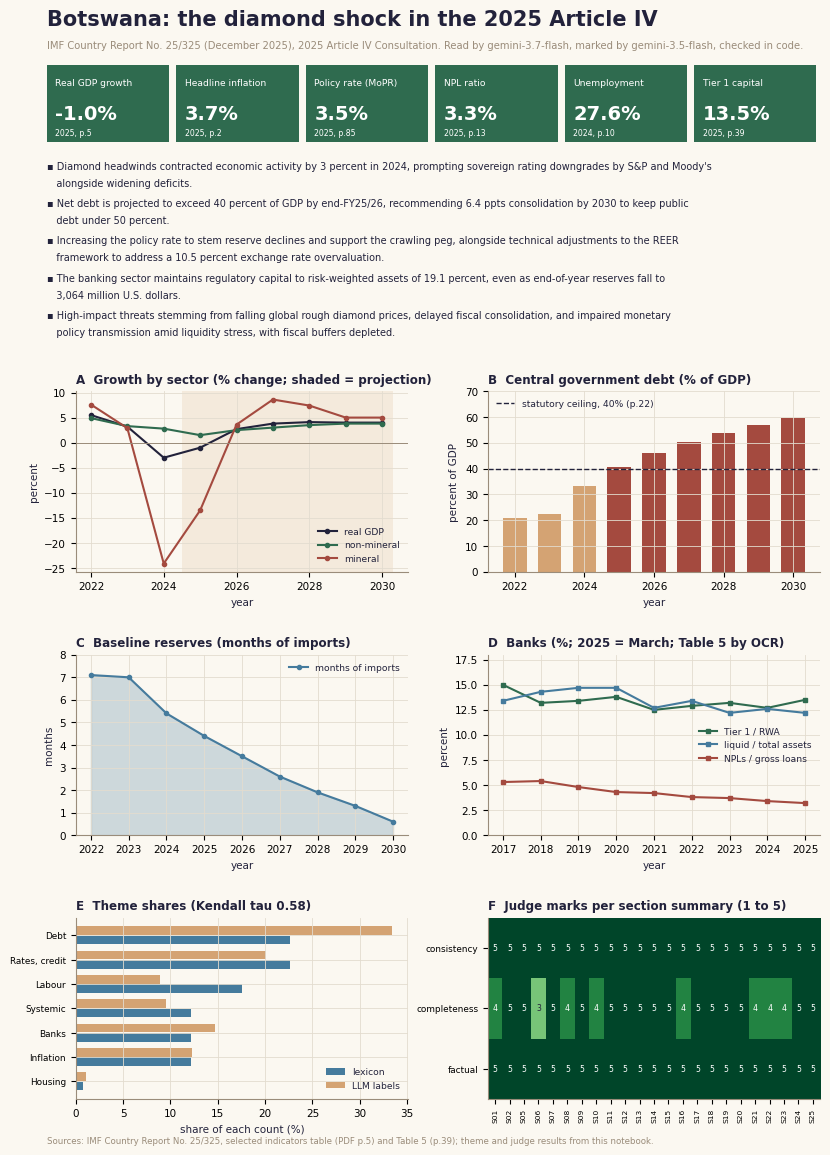

In [30]:
KALAHARI = dict(clay="#A44A3F", acacia="#2F6B4F", sand="#D4A373", dusk="#457B9D", ink="#22223B", paper="#FBF8F1", dim="#9A8C7A", rule="#E3DCCF")
plt.rcParams.update({"font.size": 7.5, "axes.titlesize": 8.6, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": KALAHARI["rule"],
                     "grid.linewidth": 0.6, "axes.facecolor": KALAHARI["paper"], "axes.edgecolor": KALAHARI["dim"], "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "legend.fontsize": 6.6, "text.color": KALAHARI["ink"], "axes.labelcolor": KALAHARI["ink"]})
board = plt.figure(figsize=(8.27, 11.69), facecolor=KALAHARI["paper"])
layout = board.add_gridspec(3, 2, left=0.075, right=0.975, top=0.655, bottom=0.05, hspace=0.46, wspace=0.24)
board.text(0.04, 0.968, "Botswana: the diamond shock in the 2025 Article IV", fontsize=15, weight="bold")
board.text(0.04, 0.948, f"{CFG.label}. Read by {CFG.writer}, marked by {CFG.judge}, checked in code.", fontsize=7.2, color=KALAHARI["dim"])
TILE = dict(zip(FIELDS, ("Real GDP growth", "Headline inflation", "Policy rate (MoPR)", "NPL ratio", "Unemployment", "Tier 1 capital")))
for n, f in enumerate(FIELDS):
    r = getattr(SHEET, f)
    left = 0.04 + n * 0.1565
    tile = board.add_axes([left, 0.868, 0.148, 0.066])
    tile.set_axis_off()
    tile.add_patch(plt.Rectangle((0, 0), 1, 1, transform=tile.transAxes, color=KALAHARI["acacia"] if r.value is not None else KALAHARI["rule"]))
    tile.text(0.07, 0.74, TILE[f], transform=tile.transAxes, color="white", fontsize=6.6)
    tile.text(0.07, 0.3, "null" if r.value is None else f"{r.value:.1f}%", transform=tile.transAxes, color="white", fontsize=14, weight="bold")
    tile.text(0.07, 0.09, f"{r.year}, p.{r.pdf_page}" if r.value is not None else "not printed", transform=tile.transAxes, color="white", fontsize=5.6)
y = 0.852
for b in EXEC.bullets[:5]:
    plain = re.sub(r"^Section S\d+ (?:reports|warns|recommends|identifies)(?: that)? ", "", b.sentence)
    for k, line in enumerate(textwrap.wrap(plain[0].upper() + plain[1:], 128)):
        board.text(0.04, y, ("\u25aa " if k == 0 else "   ") + line, fontsize=7, va="top")
        y -= 0.0145
    y -= 0.003


def series(frame, row):
    return frame[frame.row == row].sort_values("year")


ax = board.add_subplot(layout[0, 0])
for row, colour, name in [("Real GDP", KALAHARI["ink"], "real GDP"), ("Nonmineral", KALAHARI["acacia"], "non-mineral"), ("Mineral", KALAHARI["clay"], "mineral")]:
    d = series(macro, row)
    ax.plot(d.year, d.value, marker="o", ms=3, lw=1.5, color=colour, label=name)
ax.axvspan(2024.5, 2030.3, color=KALAHARI["sand"], alpha=0.16, lw=0)
ax.axhline(0, color=KALAHARI["dim"], lw=0.7)
ax.set(title="A  Growth by sector (% change; shaded = projection)", xlabel="year", ylabel="percent")
ax.legend(loc="lower right")

ax = board.add_subplot(layout[0, 1])
d = series(macro, "Total central government debt")
ax.bar(d.year, d.value, color=[KALAHARI["clay"] if v > 40 else KALAHARI["sand"] for v in d.value], width=0.68)
ax.axhline(40, color=KALAHARI["ink"], ls="--", lw=1, label="statutory ceiling, 40% (p.22)")
ax.set(title="B  Central government debt (% of GDP)", xlabel="year", ylabel="percent of GDP", ylim=(0, 70))
ax.legend(loc="upper left")

ax = board.add_subplot(layout[1, 0])
d = series(macro, "Months of imports of goods and services")
ax.fill_between(d.year, d.value, color=KALAHARI["dusk"], alpha=0.25)
ax.plot(d.year, d.value, marker="o", ms=3, color=KALAHARI["dusk"], label="months of imports")
ax.set(title="C  Baseline reserves (months of imports)", xlabel="year", ylabel="months", ylim=(0, 8))
ax.legend(loc="upper right")

ax = board.add_subplot(layout[1, 1])
for row, colour, name in [("Regulatory tier 1 capital to risk-weighted assets", KALAHARI["acacia"], "Tier 1 / RWA"), ("Liquid assets to total assets", KALAHARI["dusk"], "liquid / total assets"),
                          ("Nonperforming loans to total gross loans", KALAHARI["clay"], "NPLs / gross loans")]:
    d = series(banks, row)
    ax.plot(d.year, d.value, marker="s", ms=2.8, lw=1.5, color=colour, label=name)
ax.set(title="D  Banks (%; 2025 = March; Table 5 by OCR)", xlabel="year", ylabel="percent", ylim=(0, 18))
ax.legend(loc="center right")

ax = board.add_subplot(layout[2, 0])
order = themes.sort_values("lexicon_matches").theme.tolist()
ypos = np.arange(len(order))
for shift, method, colour, name in [(-0.19, "lexicon", KALAHARI["dusk"], "lexicon"), (0.19, "labels", KALAHARI["sand"], "LLM labels")]:
    ax.barh(ypos + shift, theme_long[theme_long.method == method].set_index("theme").loc[order, "share"], height=0.36, color=colour, label=name)
SHORT = {"Inflation & Prices": "Inflation", "Interest Rates & Credit": "Rates, credit", "Housing & Real Estate": "Housing", "Banking Capital & Liquidity": "Banks",
         "Sovereign Debt": "Debt", "Labor Market Dynamics": "Labour", "Systemic Financial Risk": "Systemic"}
ax.set_yticks(ypos, [SHORT[t] for t in order], fontsize=6.4)
ax.set(title=f"E  Theme shares (Kendall tau {tau_any.statistic:.2f})", xlabel="share of each count (%)")
ax.legend(loc="lower right")

ax = board.add_subplot(layout[2, 1])
grid = marks_long.pivot(index="criterion", columns="sid", values="mark").loc[["consistency", "completeness", "factual_alignment"]]
ax.imshow(grid.values, cmap="YlGn", vmin=1, vmax=5, aspect="auto")
for (i, j), v in np.ndenumerate(grid.values):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=5.6, color="white" if v >= 4 else KALAHARI["ink"])
ax.set_xticks(range(grid.shape[1]), grid.columns, rotation=90, fontsize=5.4)
ax.set_yticks(range(3), ["consistency", "completeness", "factual"], fontsize=6.4)
ax.grid(False)
ax.set(title="F  Judge marks per section summary (1 to 5)")
board.text(0.04, 0.012, "Sources: IMF Country Report No. 25/325, selected indicators table (PDF p.5) and Table 5 (p.39); theme and judge results from this notebook.", fontsize=6.2, color=KALAHARI["dim"])
board.savefig(CFG.results / "dashboard.png", dpi=300, facecolor=board.get_facecolor())
plt.show()

**Extension chart**

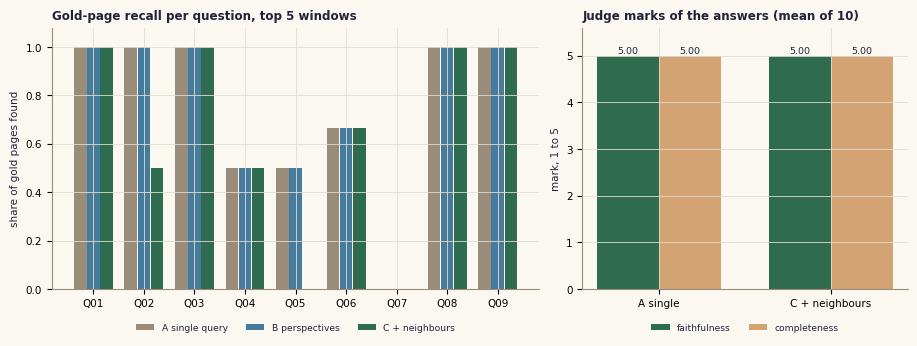

In [31]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9.2, 3.5), facecolor=KALAHARI["paper"], gridspec_kw={"width_ratios": [1.5, 1]})
view = has_gold.reset_index(drop=True)
for shift, arm, colour, name in [(-0.26, "A", KALAHARI["dim"], "A single query"), (0, "B", KALAHARI["dusk"], "B perspectives"), (0.26, "C", KALAHARI["acacia"], "C + neighbours")]:
    left.bar(view.index + shift, view[f"{arm}_gold_recall"], width=0.25, color=colour, label=name)
left.set_xticks(view.index, view.qid)
left.set(title="Gold-page recall per question, top 5 windows", ylim=(0, 1.08), ylabel="share of gold pages found")
left.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
pair = summary.dropna(subset=["faithfulness"])
xs = np.arange(len(pair))
right.bar(xs - 0.18, pair.faithfulness, width=0.36, color=KALAHARI["acacia"], label="faithfulness")
right.bar(xs + 0.18, pair.completeness, width=0.36, color=KALAHARI["sand"], label="completeness")
right.set_xticks(xs, ["A single", "C + neighbours"])
right.set(title="Judge marks of the answers (mean of 10)", ylim=(0, 5.6), ylabel="mark, 1 to 5")
for bars in right.containers:
    right.bar_label(bars, fmt="%.2f", fontsize=6.8)
right.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(CFG.results / "extension.png", dpi=300, facecolor=fig.get_facecolor())
plt.show()

**Run record**

This saves the model calls, the prompts and the hand checks.

In [32]:
log = pd.DataFrame(CALL_LOG)
save("call_log", {"writer": CFG.writer, "judge": CFG.judge, "calls": len(log), "live": int((log.source == "live").sum()), "from_ledger": int((log.source == "ledger").sum()),
                  "repairs": int(log.repair.sum()), "rows": log})
save("prompt_book", {name: {"system": s, "template": t} for name, (s, t) in PROMPTS.items()})
save("hand_checks", compare)
print(f"{len(log)} calls: {int((log.source == 'live').sum())} live, {int((log.source == 'ledger').sum())} from the ledger, {int(log.repair.sum())} repairs")
log.groupby(["role", "model"]).agg(calls=("step", "size"), live=("source", lambda s: int((s == "live").sum())), mean_seconds=("seconds", "mean"),
                                   tokens_in=("tokens_in", "sum"), tokens_out=("tokens_out", "sum")).round(2)

132 calls: 0 live, 132 from the ledger, 0 repairs


,,calls,live,mean_seconds,tokens_in,tokens_out
role,model,,,,,
judge,gemini-3.5-flash,53,0,4.88,132751,5153
writer,gemini-3.7-flash,79,0,18.29,213968,17580


In [33]:
for f in sorted(CFG.results.glob("*")):
    print(f"{f.name:36} {f.stat().st_size / 1024:9.1f} KB")

call_log.json                             28.9 KB
chunks.json                              280.1 KB
dashboard.png                            699.6 KB
executive_summary.json                     6.1 KB
extension.png                            104.1 KB
extension_perspectives.json               18.1 KB
hand_checks.json                           3.2 KB
indicators.json                            0.2 KB
indicators_provenance.json                 5.6 KB
prompt_book.json                           7.0 KB
rag_answers.json                          12.4 KB
section_summaries.json                    41.1 KB
sections.json                              3.1 KB
strengths_vulnerabilities.json             8.4 KB
theme_counts.json                         26.1 KB
time_series.json                          24.5 KB
window_size_check.json                     0.2 KB
